# Rota Livre: reclamações de calçada e acessibilidade em São Paulo

**Global Solution 2026.2 · CitizenTech · Data Science & Statistical Computing**

**Integrantes:** Igor Davi Avelar Rosa Cesário (RM568163) · Patrick Castro Quintana (RM575906) · Rafael Menezes Viana (RM576753)

**Base:** `sp156_calcadas_acessibilidade_2026.csv`, recorte das solicitações do SP156 (Prefeitura de São Paulo, Portal de Dados Abertos, *Dados do SP156 – 2º e 3º trimestres de 2026*). Mantivemos só os serviços ligados a calçada e acessibilidade.

## 1) Contexto e perguntas de negócio

O **Rota Livre** é um app que mostra rotas acessíveis para cadeirantes, idosos e pessoas com mobilidade reduzida, desviando de barreiras na calçada (degraus, buracos, falta de rampa). As barreiras são relatadas pelos próprios usuários.

Para entender a realidade desse cidadão, analisamos as reclamações que a população já faz à Prefeitura pelo **SP156** sobre calçadas e acessibilidade, entre **abril e setembro de 2026**.

**Perguntas:**
1. Quais tipos de barreira são mais reclamados?
2. Quantas reclamações foram resolvidas e quantas continuam em aberto?
3. Quanto tempo a Prefeitura leva para finalizar um pedido?
4. Quais subprefeituras concentram mais reclamações? Como fica a Sé, onde está a Bela Vista (nosso bairro de referência)?
5. O volume de reclamações muda ao longo dos meses?

In [1]:
# ==============================
# 2) Imports, configs e leitura
# ==============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Regras dos gráficos (orientação da aula):
# - Usar matplotlib (sem seaborn)
# - Um gráfico por figura (sem subplots)
# - Não definir cores explicitamente

# No Colab, faça o upload do CSV na pasta /content antes de rodar
df = pd.read_csv("sp156_calcadas_acessibilidade_2026.csv")

print("Dimensão da base:", df.shape)
df.head()

Dimensão da base: (8361, 15)


,Data de Abertura,Data de Finalização,Meio de Comunicação,Tema,Assunto,Serviço,Status,Órgão,Logradouro,Número,CEP,Latitude,Longitude,Prefeitura Operacional,Distrito
0,2026-04-01,2026-04-01,MOBILE,Rua e bairro,"Calçadas, guias e postes",Acessibilidade - solicitar avaliação de obstác...,Cancelada,INTEGRACAO-SGF,Rua Geracina,171,8062060.0,-23.507387,-46.471565,SAO MIGUEL,VILA JACUI
1,2026-04-01,NaN,PORTAL,Rua e bairro,"Calçadas, guias e postes",Calçada particular - denunciar calçada danific...,Aberto,INTEGRACAO-SGF,Rua Ferdinando Paer,137,4475205.0,-23.701543,-46.630292,CIDADE ADEMAR,PEDREIRA
2,2026-04-01,NaN,PORTAL,Rua e bairro,Fiação e Postes,Calçada particular - denunciar calçada danific...,Aberto,INTEGRACAO-SGF,Rua Correia de Lacerda,646,3470080.0,-23.573697,-46.524379,ARICANDUVA-FORMOSA-CARRAO,ARICANDUVA
3,2026-04-01,2026-04-06,PORTAL,Rua e bairro,"Calçadas, guias e postes",Calçada pública - solicitar manutenção,Finalizada,INTEGRAÇÃO-SMGI/SGZ,Rua Professor Fonseca Lessa,18,3983210.0,-23.613723,-46.508237,SAPOPEMBA,SAPOPEMBA
4,2026-04-01,2026-05-19,CRM,Rua e bairro,Fiação e Postes,Calçada particular - denunciar calçada danific...,Finalizada,INTEGRACAO-SGF,Rua Luminárias,72,5439000.0,-23.548035,-46.688150,PINHEIROS,PINHEIROS


## 3) Visão geral da base

> **Perguntas-guia**
> - Como a base está estruturada?
> - Quais variáveis são categóricas e quais são numéricas?
> - Quais colunas são só identificação e não entram na análise?

In [2]:
df.info()
display(df.sample(5, random_state=42))
display(df.describe(include='all').transpose())

<class 'pandas.DataFrame'>
RangeIndex: 8361 entries, 0 to 8360
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Data de Abertura        8361 non-null   str    
 1   Data de Finalização     3131 non-null   str    
 2   Meio de Comunicação     8361 non-null   str    
 3   Tema                    8361 non-null   str    
 4   Assunto                 8361 non-null   str    
 5   Serviço                 8361 non-null   str    
 6   Status                  8361 non-null   str    
 7   Órgão                   8361 non-null   str    
 8   Logradouro              8361 non-null   str    
 9   Número                  8361 non-null   int64  
 10  CEP                     8361 non-null   float64
 11  Latitude                8361 non-null   float64
 12  Longitude               8361 non-null   float64
 13  Prefeitura Operacional  8347 non-null   str    
 14  Distrito                8354 non-null   str    
dty

,Data de Abertura,Data de Finalização,Meio de Comunicação,Tema,Assunto,Serviço,Status,Órgão,Logradouro,Número,CEP,Latitude,Longitude,Prefeitura Operacional,Distrito
3159,2026-05-27,NaN,PORTAL,Rua e bairro,Fiação e Postes,Acessibilidade - solicitar avaliação de obstác...,Aberto,INTEGRACAO-SGF,Rua Galileu,429,4632040.0,-23.634466,-46.665357,SANTO AMARO,CAMPO BELO
6826,2026-08-25,2026-08-25,CRM,Rua e bairro,Fiação e Postes,Sugerir construção de calçadas em áreas públic...,Finalizada,SMPR-CPO-STM-Sugestão,Rua Baltazar de Morais,45,2255010.0,-23.474636,-46.589710,SANTANA-TUCURUVI,TUCURUVI
5050,2026-07-15,NaN,MOBILE,Rua e bairro,Fiação e Postes,Acessibilidade - solicitar avaliação de obstác...,Aberto,INTEGRACAO-SGF,Rua José Eid Maluf,188,4405140.0,-23.672815,-46.657255,CIDADE ADEMAR,CIDADE ADEMAR
6309,2026-08-13,2026-08-14,PORTAL,Rua e bairro,Guias rebaixadas,Guias para travessia de pedestres - Solicitar ...,Finalizada,INTEGRACAO-CET,Avenida Horácio Lafer,540,4538082.0,-23.587789,-46.684337,PINHEIROS,ITAIM BIBI
5388,2026-07-23,NaN,CRM,Rua e bairro,Fiação e Postes,Acessibilidade - solicitar avaliação de obstác...,Aberto,INTEGRACAO-SGF,Rua Doutor Carmelo D'Agostino,156,2991040.0,-23.437555,-46.726842,PIRITUBA-JARAGUA,JARAGUA


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Data de Abertura,8361,183,2026-04-08,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Data de Finalização,3131,180,2026-08-05,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Meio de Comunicação,8361,4,PORTAL,3736,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Tema,8361,1,Rua e bairro,8361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Assunto,8361,3,Fiação e Postes,6196,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Serviço,8361,5,Calçada pública - solicitar manutenção,3082,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,8361,4,Aberto,5228,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Órgão,8361,7,INTEGRACAO-SGF,4537,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Logradouro,8361,4651,Rua Paulo de Lima Corrêia,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Número,8361.0,NaN,NaN,NaN,990.790336,15403.873208,0.0,90.0,262.0,635.0,949955.0


> **Observações**
> - Cada linha é **uma solicitação** feita ao SP156.
> - Quase todas as variáveis são **categóricas**: canal, serviço, status, subprefeitura e distrito.
> - As datas de abertura e de finalização vieram como texto e precisam virar data.
> - A variável numérica que vamos analisar é o **tempo de atendimento**, que ainda vamos criar a partir das duas datas.
> - Logradouro, número e CEP são de identificação do local e não entram nas estatísticas.

In [3]:
# ==============================
# 4) Qualidade dos dados
# ==============================
null_counts = df.isna().sum().sort_values(ascending=False)
null_pct = (df.isna().mean() * 100).round(2).sort_values(ascending=False)
display(pd.DataFrame({'nulos': null_counts, '%_nulos': null_pct}))

print('Linhas duplicadas:', df.duplicated().sum())

# Nomes que aparecem na coluna de subprefeitura
display(df['Prefeitura Operacional'].value_counts().tail(8))

# Coordenadas fora da cidade de São Paulo
lat = pd.to_numeric(df['Latitude'], errors='coerce')
lon = pd.to_numeric(df['Longitude'], errors='coerce')
fora_sp = ~lat.between(-24.1, -23.3) | ~lon.between(-47.0, -46.3)
print('Coordenadas fora de SP:', fora_sp.sum())

,nulos,%_nulos
Data de Finalização,5230,62.55
Prefeitura Operacional,14,0.17
Distrito,7,0.08
Tema,0,0.00
Assunto,0,0.00
Data de Abertura,0,0.00
Meio de Comunicação,0,0.00
Status,0,0.00
Serviço,0,0.00
Órgão,0,0.00


Linhas duplicadas: 262


Prefeitura Operacional
PERUS-ANHANGUERA                          80
CIDADE TIRADENTES                         65
PARELHEIROS                               57
Superintendencia das Usinas de Asfalto    17
CASA VERDE-CACHOEIRINHA                   14
Prefeitura Regional nao encontrada         6
PERUS                                      3
Departamento de Estradas de Rodagem        1
Name: count, dtype: int64

Coordenadas fora de SP: 4


> **Decisões de tratamento**
> - **Data de Finalização nula:** é esperado, porque são os pedidos ainda em aberto. **Mantemos** os nulos e usamos o status para separar.
> - **Duplicados:** são linhas idênticas em todas as colunas (mesmo dia, serviço e endereço). Como a base não tem número de protocolo, tratamos como registro repetido e **removemos**.
> - **Subprefeitura:** juntamos nomes escritos de forma diferente (*CASA VERDE-CACHOEIRINHA* e *PERUS*). Os registros com órgãos que não são subprefeituras, ou sem informação, viram **NÃO IDENTIFICADA**.
> - **Coordenadas fora de SP:** viram nulo, para não aparecerem fora do mapa.

In [4]:
# ==============================
# 5) Preparação
# ==============================
df_clean = df.drop_duplicates().copy()

df_clean = df_clean.rename(columns={
    'Data de Abertura': 'data_abertura', 'Data de Finalização': 'data_finalizacao',
    'Meio de Comunicação': 'canal', 'Tema': 'tema', 'Assunto': 'assunto', 'Serviço': 'servico',
    'Status': 'status', 'Órgão': 'orgao', 'Logradouro': 'logradouro', 'Número': 'numero', 'CEP': 'cep',
    'Latitude': 'latitude', 'Longitude': 'longitude',
    'Prefeitura Operacional': 'subprefeitura', 'Distrito': 'distrito'
})

# Tipos
df_clean['data_abertura'] = pd.to_datetime(df_clean['data_abertura'], errors='coerce')
df_clean['data_finalizacao'] = pd.to_datetime(df_clean['data_finalizacao'], errors='coerce')
df_clean['latitude'] = pd.to_numeric(df_clean['latitude'], errors='coerce')
df_clean['longitude'] = pd.to_numeric(df_clean['longitude'], errors='coerce')

# Subprefeitura padronizada
df_clean['subprefeitura'] = df_clean['subprefeitura'].replace({
    'CASA VERDE-CACHOEIRINHA': 'CASA VERDE-LIMAO-CACHOEIRINHA',
    'PERUS': 'PERUS-ANHANGUERA'
})
nao_sub = ['Superintendencia das Usinas de Asfalto', 'Prefeitura Regional nao encontrada',
           'Departamento de Estradas de Rodagem']
df_clean.loc[df_clean['subprefeitura'].isin(nao_sub) | df_clean['subprefeitura'].isna(),
             'subprefeitura'] = 'NÃO IDENTIFICADA'

# Coordenadas fora de SP viram nulo
fora = ~df_clean['latitude'].between(-24.1, -23.3) | ~df_clean['longitude'].between(-47.0, -46.3)
df_clean.loc[fora, ['latitude', 'longitude']] = np.nan

# Categoria curta da barreira
df_clean['categoria'] = df_clean['servico'].map({
    'Calçada pública - solicitar manutenção': 'Calçada pública danificada',
    'Acessibilidade - solicitar avaliação de obstáculo na calçada': 'Obstáculo na calçada',
    'Calçada particular - denunciar calçada danificada ou inexistente': 'Calçada particular danificada',
    'Guias para travessia de pedestres - Solicitar rebaixamento': 'Falta de rampa na travessia',
    'Sugerir construção de calçadas em áreas públicas e praças': 'Falta de calçada'
})

# Mês de abertura
df_clean['mes'] = df_clean['data_abertura'].dt.month

# Tempo de atendimento (só para pedidos finalizados)
finalizada = df_clean['status'] == 'Finalizada'
df_clean['tempo_dias'] = np.where(
    finalizada, (df_clean['data_finalizacao'] - df_clean['data_abertura']).dt.days, np.nan)

print('Dimensão após a preparação:', df_clean.shape)
df_clean[['data_abertura', 'categoria', 'status', 'subprefeitura', 'tempo_dias']].head()

Dimensão após a preparação: (8099, 18)


,data_abertura,categoria,status,subprefeitura,tempo_dias
0,2026-04-01,Obstáculo na calçada,Cancelada,SAO MIGUEL,NaN
1,2026-04-01,Calçada particular danificada,Aberto,CIDADE ADEMAR,NaN
2,2026-04-01,Calçada particular danificada,Aberto,ARICANDUVA-FORMOSA-CARRAO,NaN
3,2026-04-01,Calçada pública danificada,Finalizada,SAPOPEMBA,5.0
4,2026-04-01,Calçada particular danificada,Finalizada,PINHEIROS,48.0


## 6) Tipos de barreira (pergunta 1)

,quantidade,%
categoria,,
Calçada pública danificada,2979,36.8
Obstáculo na calçada,2493,30.8
Calçada particular danificada,1896,23.4
Falta de rampa na travessia,452,5.6
Falta de calçada,279,3.4


Moda (categoria mais frequente): Calçada pública danificada


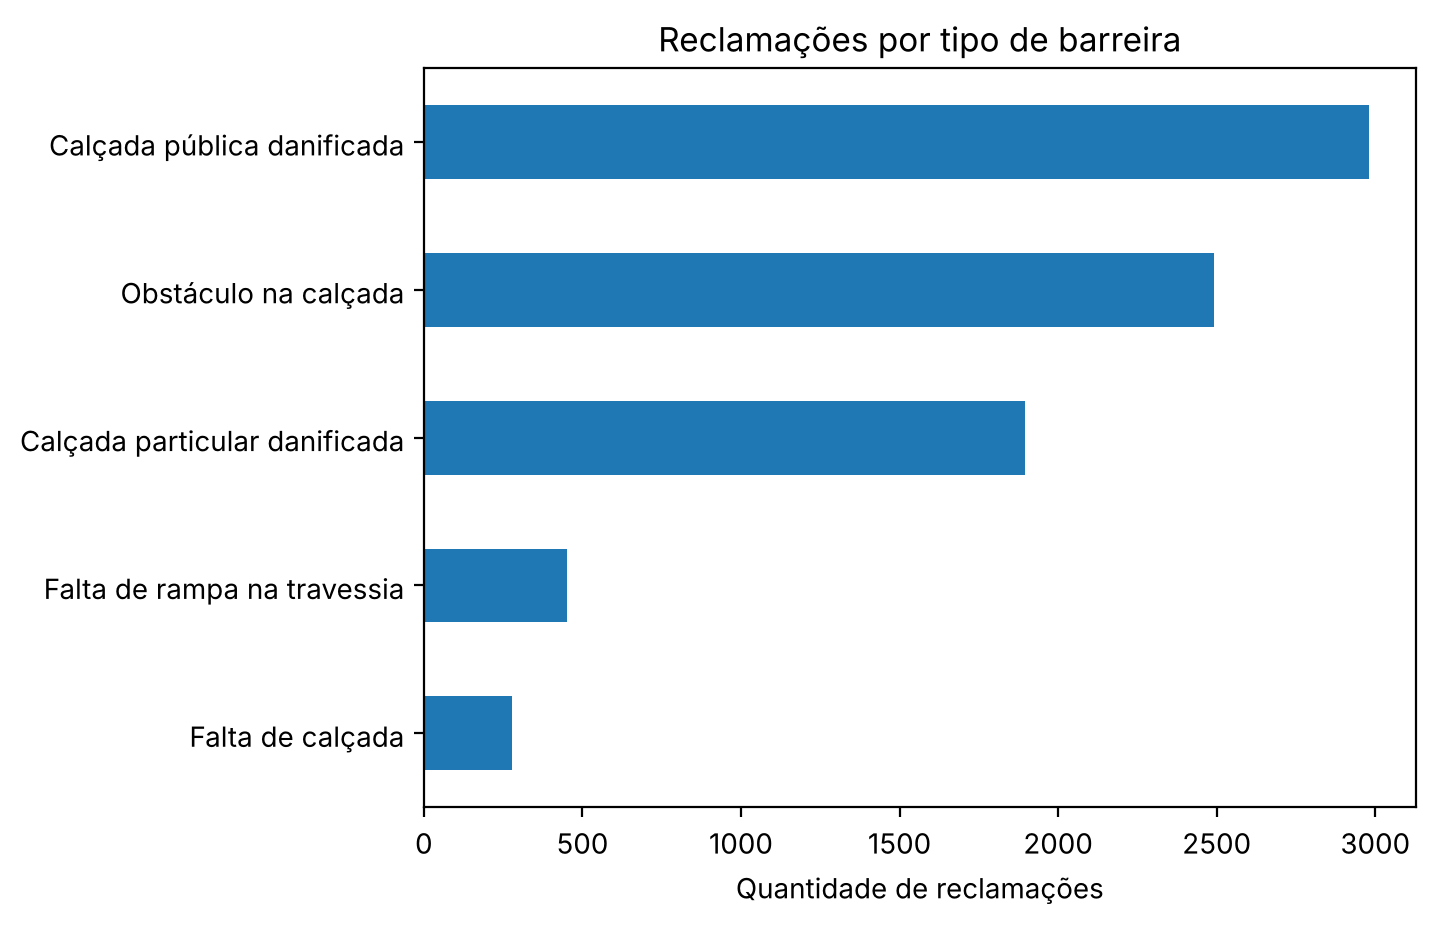

In [5]:
freq_cat = df_clean['categoria'].value_counts()
tab_cat = pd.DataFrame({'quantidade': freq_cat,
                        '%': (freq_cat / freq_cat.sum() * 100).round(1)})
display(tab_cat)
print('Moda (categoria mais frequente):', df_clean['categoria'].mode()[0])

plt.figure()
freq_cat.sort_values().plot(kind='barh', title='Reclamações por tipo de barreira')
plt.xlabel('Quantidade de reclamações')
plt.ylabel('')
plt.show()

> **Interpretação**
> - A **calçada pública danificada** é a reclamação mais comum (moda): 36,8% dos pedidos.
> - Em seguida vem o **obstáculo na calçada** (30,8%), que é exatamente a barreira que o Rota Livre quer mapear.
> - Somando calçada pública e particular, **60% das reclamações** são sobre calçada em mau estado.

## 7) Situação dos pedidos (pergunta 2)

,quantidade,%
status,,
Aberto,5036,62.2
Finalizada,3042,37.6
Cancelada,19,0.2
Em Andamento,2,0.0


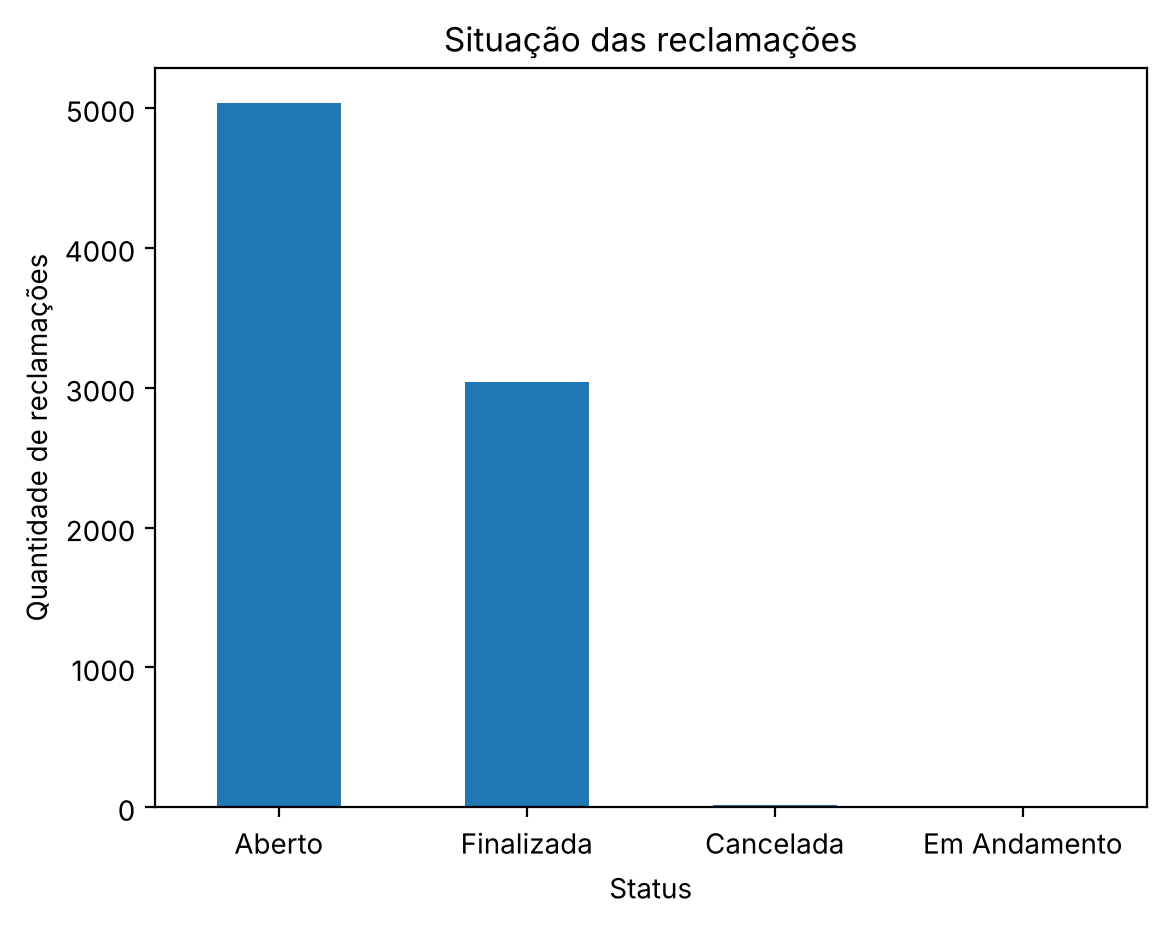

status,Aberto,Cancelada,Em Andamento,Finalizada
categoria,,,,
Calçada particular danificada,88.3,0.5,0.1,11.1
Calçada pública danificada,34.7,0.2,0.0,65.1
Falta de calçada,1.1,0.0,0.0,98.9
Falta de rampa na travessia,17.0,0.0,0.0,83.0
Obstáculo na calçada,90.1,0.2,0.0,9.6


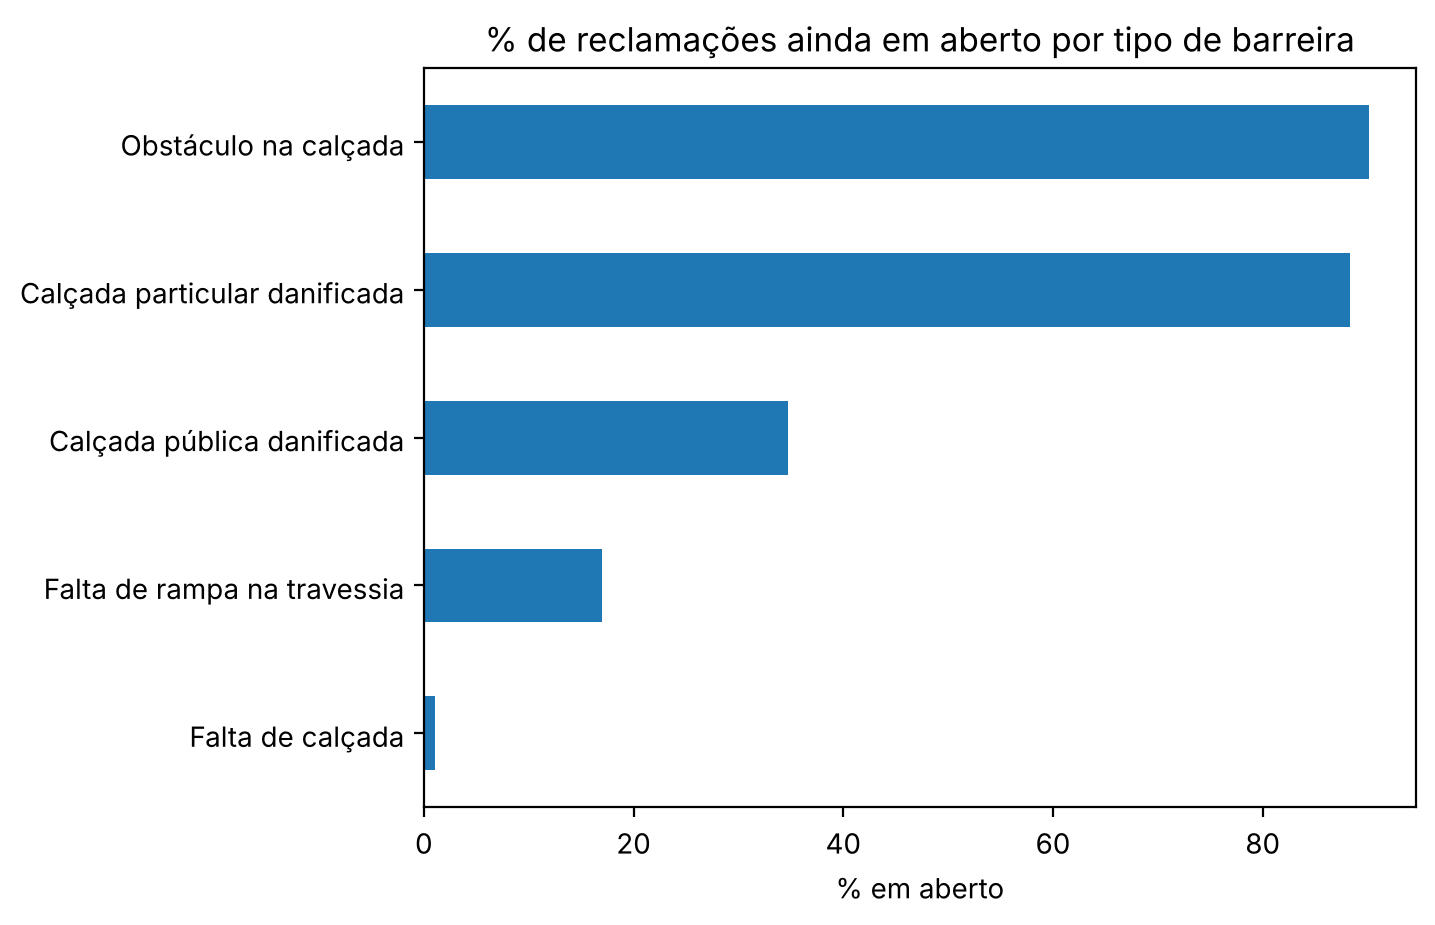

In [6]:
freq_status = df_clean['status'].value_counts()
display(pd.DataFrame({'quantidade': freq_status,
                      '%': (freq_status / freq_status.sum() * 100).round(1)}))

plt.figure()
freq_status.plot(kind='bar', title='Situação das reclamações')
plt.xlabel('Status')
plt.ylabel('Quantidade de reclamações')
plt.xticks(rotation=0)
plt.show()

# % de pedidos em aberto por tipo de barreira
status_cat = (pd.crosstab(df_clean['categoria'], df_clean['status'], normalize='index') * 100).round(1)
display(status_cat)

plt.figure()
status_cat['Aberto'].sort_values().plot(kind='barh', title='% de reclamações ainda em aberto por tipo de barreira')
plt.xlabel('% em aberto')
plt.ylabel('')
plt.show()

> **Interpretação**
> - **62,2%** das reclamações ainda estavam **em aberto** quando os dados foram publicados.
> - O pior caso é o **obstáculo na calçada**: **90,1%** continuam em aberto, e a calçada particular danificada tem 88,3%.
> - Ou seja, a barreira que mais atrapalha o cadeirante é justamente a que menos se resolve. Enquanto ela não é consertada, o cidadão precisa saber por onde desviar, e é aí que o Rota Livre ajuda.

## 8) Tempo de atendimento (pergunta 3)

Só entram aqui os **3.042 pedidos finalizados**, porque os outros ainda não têm data de finalização.

In [7]:
t = df_clean['tempo_dias'].dropna()

q1 = t.quantile(0.25)
q2 = t.quantile(0.50)
q3 = t.quantile(0.75)
iqr = q3 - q1

resumo_tempo = pd.Series({
    'quantidade': t.count(),
    'média': t.mean(),
    'mediana': q2,
    'moda': t.mode()[0],
    'mínimo': t.min(),
    'máximo': t.max(),
    'amplitude': t.max() - t.min(),
    'variância': t.var(),
    'desvio-padrão': t.std(),
    'coef. de variação': t.std() / t.mean(),
    'Q1 (25%)': q1,
    'Q3 (75%)': q3,
    'IQR': iqr,
    'percentil 90': t.quantile(0.90),
    'assimetria': t.skew()
}).round(2)
display(resumo_tempo.to_frame('tempo_dias'))

,tempo_dias
quantidade,3042.00
média,14.44
mediana,5.00
moda,1.00
mínimo,0.00
máximo,123.00
amplitude,123.00
variância,463.56
desvio-padrão,21.53
coef. de variação,1.49


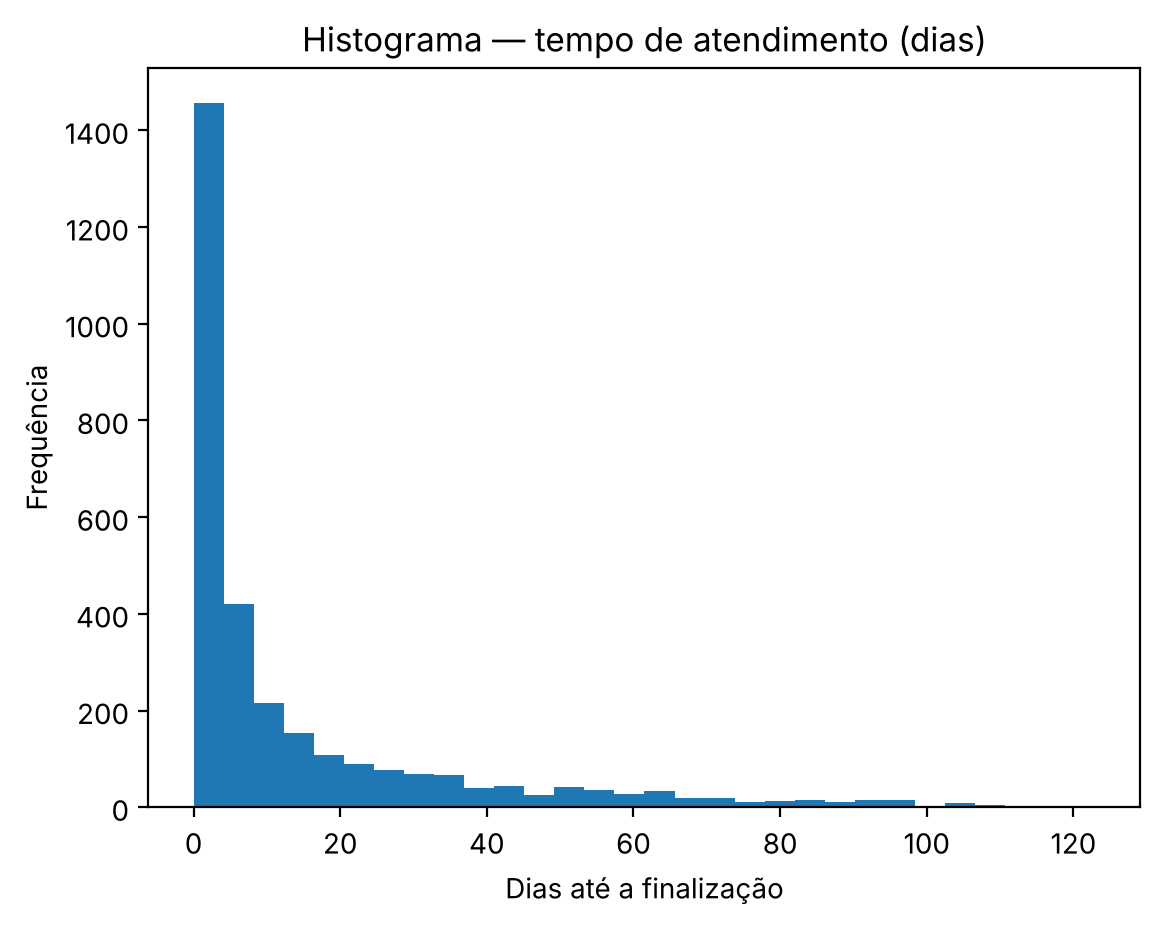

In [8]:
plt.figure()
t.plot(kind='hist', bins=30, title='Histograma — tempo de atendimento (dias)')
plt.xlabel('Dias até a finalização')
plt.ylabel('Frequência')
plt.show()

> **Interpretação**
> - A **média (14,4 dias)** é quase o triplo da **mediana (5 dias)**, e a **moda é 1 dia**. Isso mostra que muitos pedidos são finalizados rápido, mas alguns demoram muito e puxam a média para cima.
> - A **assimetria é positiva (2,21)**: o histograma tem uma cauda longa para a direita.
> - A dispersão é alta: o desvio-padrão (21,5 dias) é maior que a média, e o coeficiente de variação é 1,49.
> - Metade dos pedidos finalizados leva até 5 dias, mas **10% levam 45 dias ou mais**.

In [9]:
# ==============================
# Outliers do tempo (IQR e Z-Score)
# ==============================
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr
outliers_iqr = df_clean[df_clean['tempo_dias'] > lim_sup]
print(f'Limite superior (IQR): {lim_sup:.1f} dias')
print('Outliers (IQR):', outliers_iqr.shape[0])

z = (t - t.mean()) / t.std(ddof=0)
print('Outliers (|z| >= 3):', (abs(z) >= 3).sum())

display(outliers_iqr['categoria'].value_counts())

Limite superior (IQR): 43.5 dias
Outliers (IQR): 318
Outliers (|z| >= 3): 82


categoria
Calçada pública danificada       167
Calçada particular danificada     71
Obstáculo na calçada              71
Falta de rampa na travessia        9
Name: count, dtype: int64

> **Discussão**
> - Pelo IQR, pedidos com mais de **43,5 dias** são outliers (318 casos). Pelo Z-score, 82 casos.
> - **Não removemos** esses pedidos: eles não são erro de digitação, são casos reais de demora. Para o cidadão, esses são justamente os pedidos que mais importam.

,finalizados,média (dias),mediana (dias)
categoria,,,
Obstáculo na calçada,240,34.0,28.0
Calçada particular danificada,211,36.2,27.0
Calçada pública danificada,1940,13.1,5.0
Falta de rampa na travessia,375,7.3,3.0
Falta de calçada,276,0.0,0.0


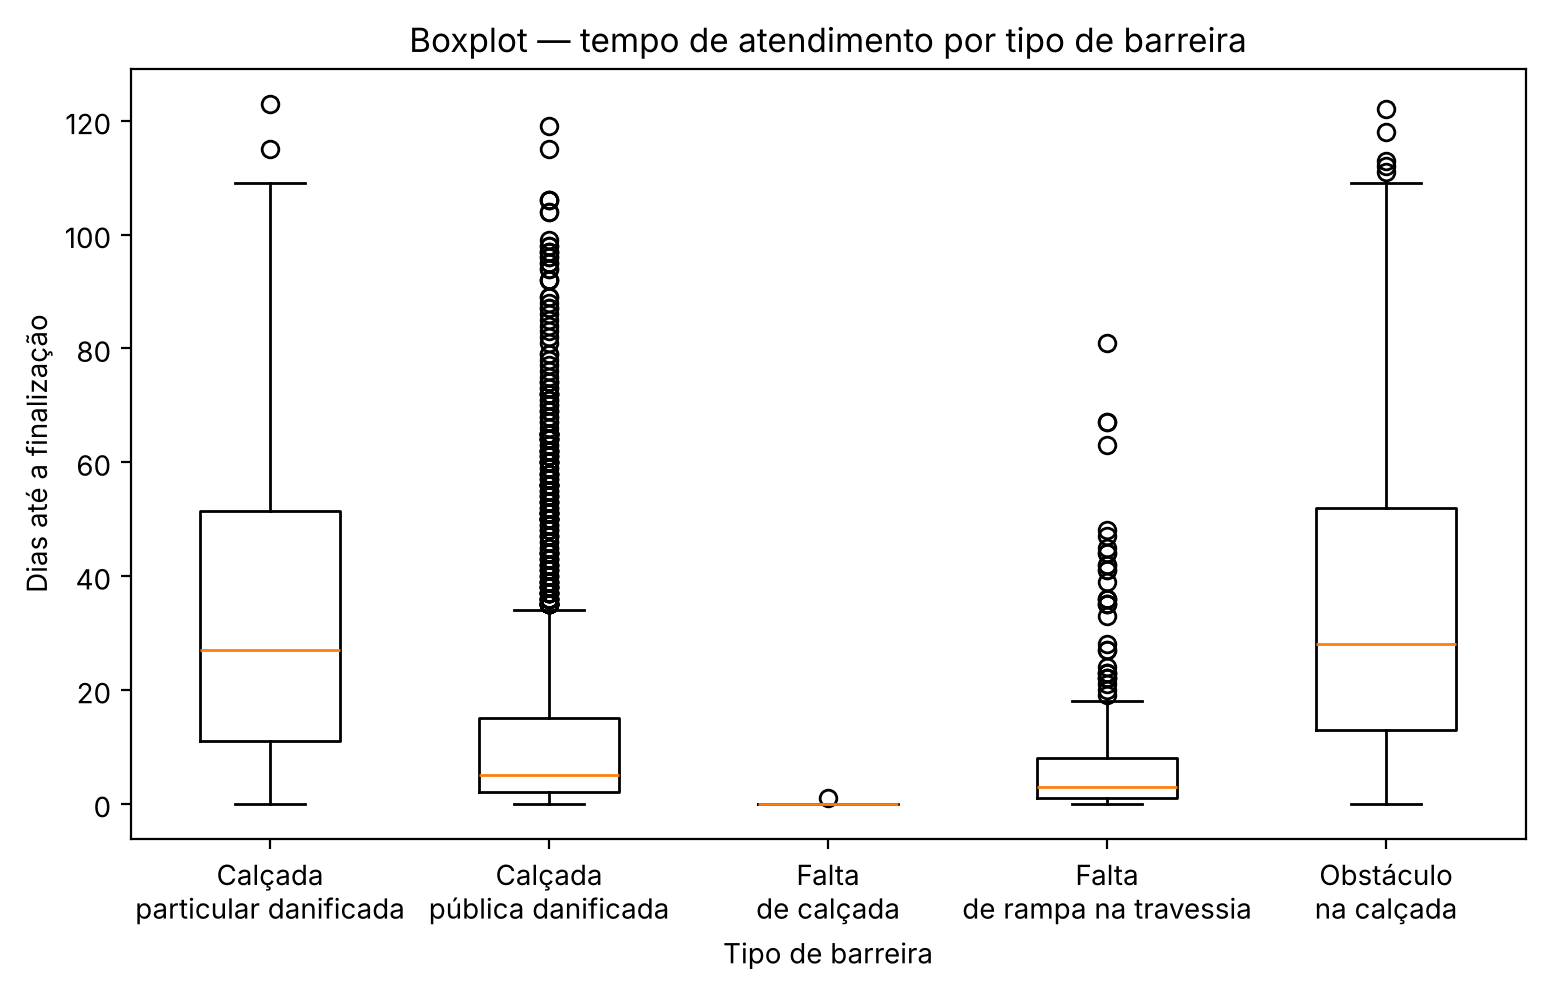

In [10]:
tempo_cat = df_clean.groupby('categoria')['tempo_dias'].agg(['count', 'mean', 'median']).round(1)
tempo_cat.columns = ['finalizados', 'média (dias)', 'mediana (dias)']
display(tempo_cat.sort_values('mediana (dias)', ascending=False))

# Boxplot por tipo de barreira (um gráfico por figura)
grupos = []
labels = []
for cat, subset in df_clean.groupby('categoria'):
    valores = subset['tempo_dias'].dropna().values
    if len(valores) > 0:
        grupos.append(valores)
        labels.append(cat.replace(' ', '\n', 1))

plt.figure(figsize=(9, 5))
plt.boxplot(grupos, showfliers=True)
plt.xticks(range(1, len(labels) + 1), labels)
plt.title('Boxplot — tempo de atendimento por tipo de barreira')
plt.xlabel('Tipo de barreira')
plt.ylabel('Dias até a finalização')
plt.show()

> **Interpretação**
> - O **obstáculo na calçada** tem mediana de **28 dias**, contra 5 dias da calçada pública. Mesmo quando é resolvido, ele demora muito mais.
> - **Falta de calçada** aparece com 0 dias porque é uma *sugestão*: o pedido é respondido no mesmo dia, e isso não quer dizer que a calçada foi construída. Por isso, "finalizada" nem sempre significa "problema resolvido na rua".

## 9) Onde estão as reclamações (pergunta 4)

,quantidade,%
subprefeitura,,
SE,623,7.7
SANTO AMARO,504,6.2
PINHEIROS,440,5.4
VILA MARIANA,438,5.4
MOOCA,423,5.2
IPIRANGA,377,4.7
PIRITUBA-JARAGUA,343,4.2
BUTANTA,342,4.2
LAPA,334,4.1


Média de reclamações por subprefeitura: 252.0
Mediana de reclamações por subprefeitura: 207.0
Posição da Sé no ranking: 1 de 32


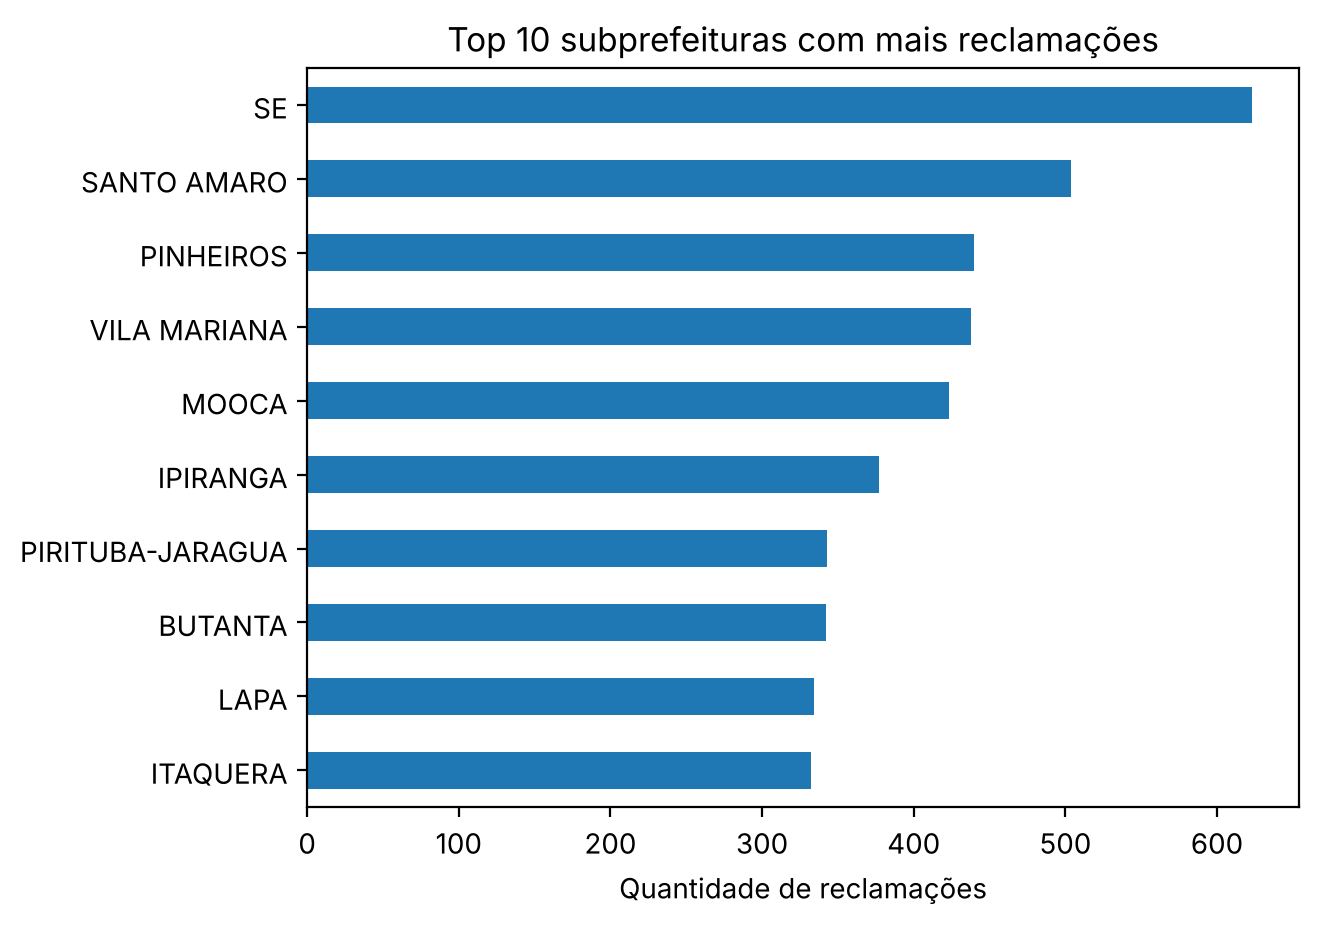

In [11]:
freq_sub = df_clean['subprefeitura'].value_counts()
top10 = freq_sub.head(10)
display(pd.DataFrame({'quantidade': top10, '%': (top10 / freq_sub.sum() * 100).round(1)}))

sub_validas = freq_sub.drop('NÃO IDENTIFICADA', errors='ignore')
print('Média de reclamações por subprefeitura:', round(sub_validas.mean(), 1))
print('Mediana de reclamações por subprefeitura:', sub_validas.median())
print('Posição da Sé no ranking:', list(sub_validas.index).index('SE') + 1, 'de', len(sub_validas))

plt.figure()
top10.sort_values().plot(kind='barh', title='Top 10 subprefeituras com mais reclamações')
plt.xlabel('Quantidade de reclamações')
plt.ylabel('')
plt.show()

In [12]:
# Dentro da Sé: distritos e ruas da Bela Vista
se = df_clean[df_clean['subprefeitura'] == 'SE']
display(se['distrito'].value_counts().head(8).to_frame('reclamações na Sé'))

bela_vista = se[se['distrito'] == 'BELA VISTA']
print('Reclamações na Bela Vista:', len(bela_vista))
display(bela_vista['logradouro'].value_counts().head(5).to_frame('reclamações'))

,reclamações na Sé
distrito,
CONSOLACAO,109
SANTA CECILIA,108
REPUBLICA,101
LIBERDADE,70
BELA VISTA,68
CAMBUCI,58
BOM RETIRO,50
SE,47


Reclamações na Bela Vista: 68


,reclamações
logradouro,
Rua Treze de Maio,7
Rua Doutor Seng,4
Rua Almirante Marques de Leão,4
Rua Frei Caneca,3
Rua dos Franceses,3


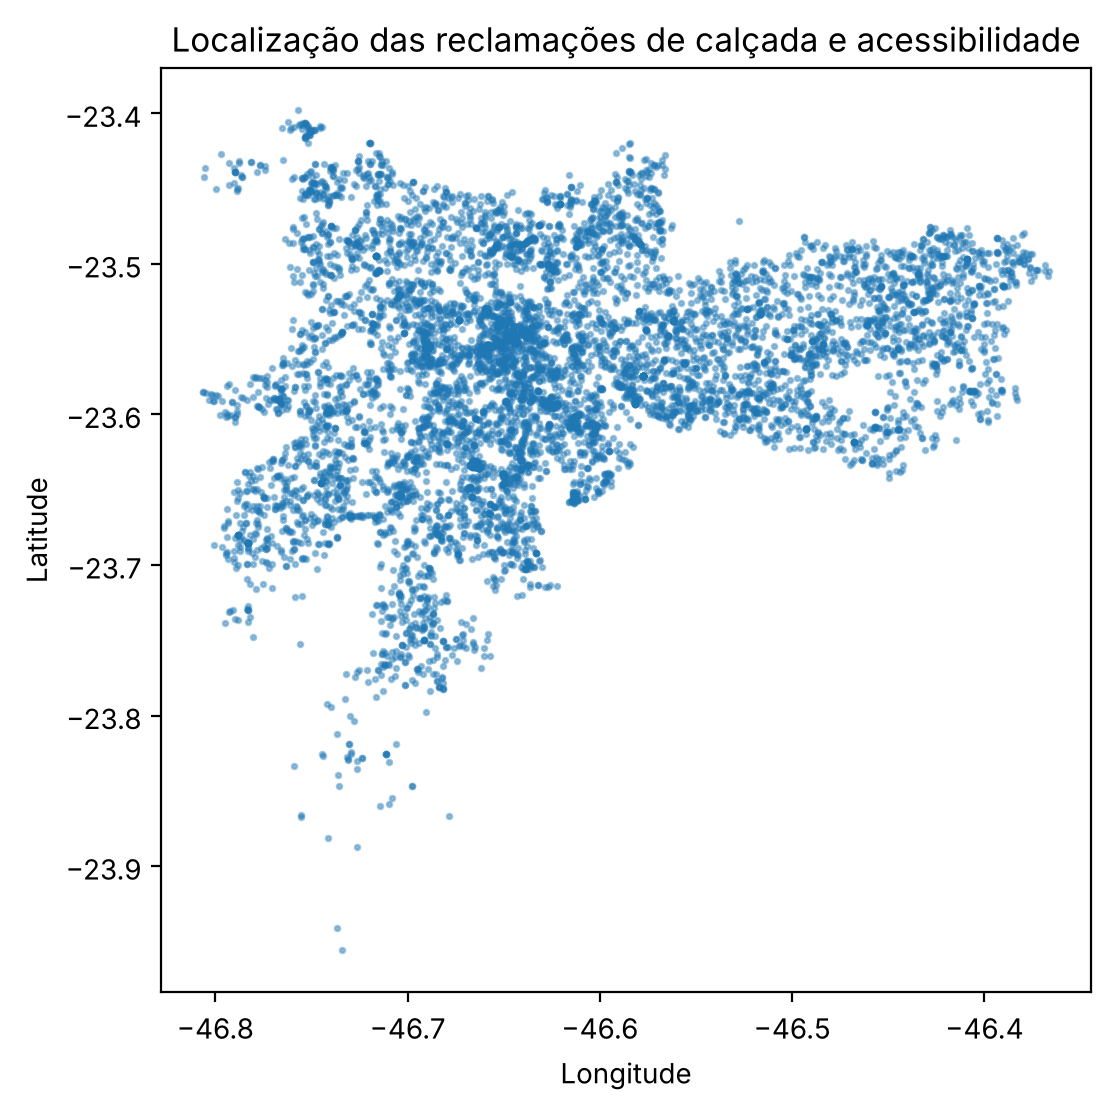

In [13]:
# Mapa simples com a localização das reclamações
plt.figure(figsize=(6, 6))
plt.scatter(df_clean['longitude'], df_clean['latitude'], s=3, alpha=0.4)
plt.title('Localização das reclamações de calçada e acessibilidade')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.show()

> **Interpretação**
> - A **Sé** é a subprefeitura com **mais reclamações (623)**, quase **2,5 vezes a média** das subprefeituras (252).
> - Dentro da Sé, a **Bela Vista** teve 68 reclamações. As ruas que mais aparecem são a Rua Treze de Maio, a Rua Doutor Seng e a Rua Almirante Marques de Leão, bem perto da Paulista.
> - O mapa mostra reclamações na cidade toda, com mais pontos na região central, onde circula mais gente a pé.
> - Isso confirma a escolha da Bela Vista como bairro de referência do Rota Livre.

## 10) Evolução no tempo (pergunta 5)

,reclamações
mes,
Abr,1826
Mai,1438
Jun,1115
Jul,1176
Ago,1337
Set,1207


Média mensal: 1349.8 | Desvio-padrão: 260.9


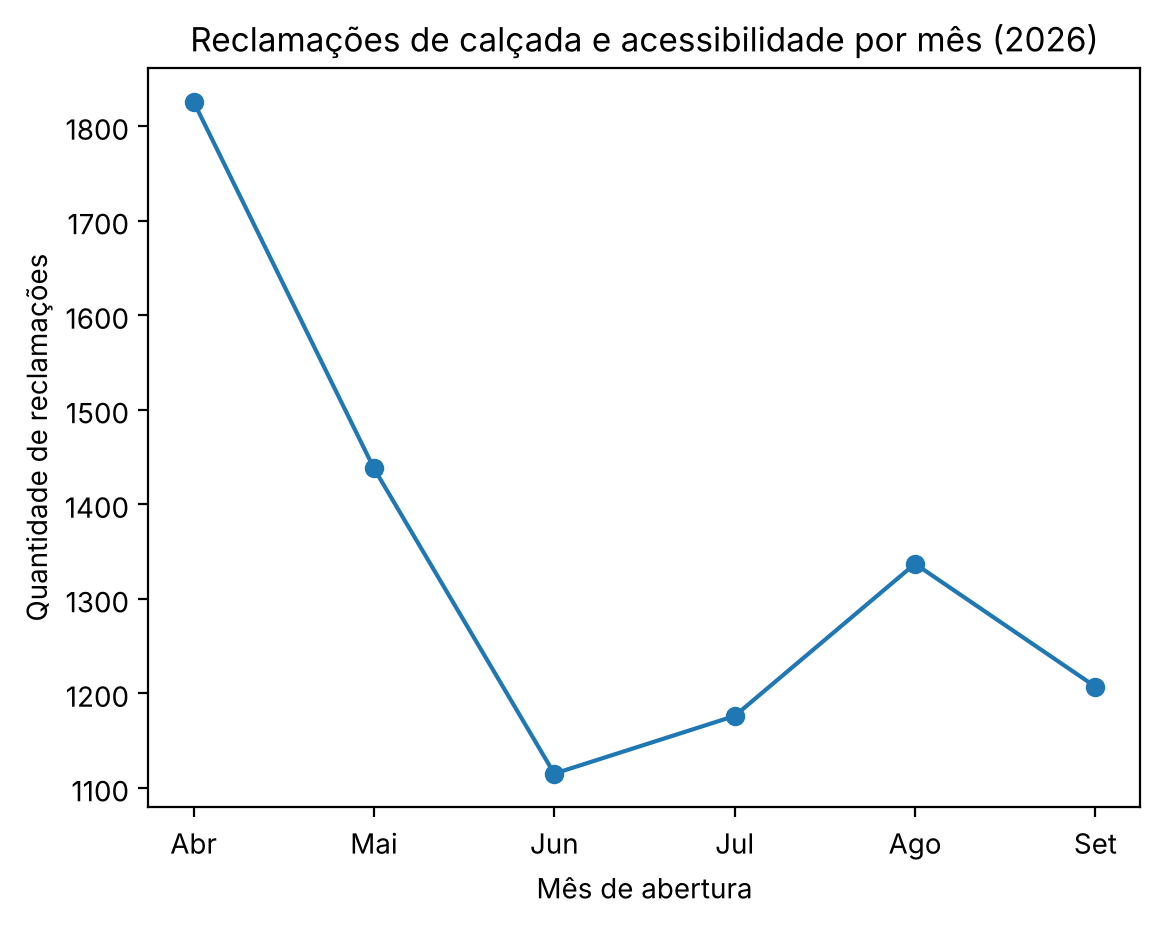

In [14]:
nomes_mes = {4: 'Abr', 5: 'Mai', 6: 'Jun', 7: 'Jul', 8: 'Ago', 9: 'Set'}
por_mes = df_clean.groupby('mes').size().rename(index=nomes_mes)
display(por_mes.to_frame('reclamações'))
print('Média mensal:', round(por_mes.mean(), 1), '| Desvio-padrão:', round(por_mes.std(), 1))

plt.figure()
por_mes.plot(kind='line', marker='o', title='Reclamações de calçada e acessibilidade por mês (2026)')
plt.xlabel('Mês de abertura')
plt.ylabel('Quantidade de reclamações')
plt.show()

> **Interpretação**
> - **Abril** teve o maior volume (1.826 pedidos). Depois, o número ficou entre 1.100 e 1.450 por mês.
> - Não há uma tendência clara de queda ou de alta: chegam, em média, cerca de **1.350 reclamações por mês**.

In [15]:
# Por onde o cidadão faz a reclamação
freq_canal = df_clean['canal'].value_counts()
display(pd.DataFrame({'quantidade': freq_canal, '%': (freq_canal / freq_canal.sum() * 100).round(1)}))

,quantidade,%
canal,,
PORTAL,3573,44.1
CRM,2840,35.1
MOBILE,1255,15.5
CHATBOT,431,5.3


> **Observação:** 44% dos pedidos vêm do Portal e 35% do CRM, que reúne os registros feitos pela central de atendimento. Uma parte grande da população ainda depende de atendimento humano, o que reforça a ideia da Central Rota Livre como ponto físico.

## 11) Conclusões

**Respostas às perguntas**
1. **Tipos de barreira:** a calçada pública danificada lidera (36,8%), seguida do obstáculo na calçada (30,8%).
2. **Situação:** 62,2% das reclamações seguem em aberto. No obstáculo na calçada, são 90,1%.
3. **Tempo:** a mediana é de 5 dias, mas a distribuição é assimétrica (média de 14,4 dias, 10% acima de 45 dias). O obstáculo na calçada tem mediana de 28 dias.
4. **Onde:** a Sé é a subprefeitura com mais reclamações (623), e a Bela Vista teve 68.
5. **Tempo:** cerca de 1.350 reclamações por mês, com pico em abril.

**O que isso significa para o Rota Livre**
- As barreiras demoram para ser resolvidas, então mostrar o desvio na hora é útil para o cidadão.
- A Bela Vista e o centro concentram as reclamações e são um bom lugar para começar.
- Os dados do SP156 podem ajudar a montar o primeiro mapa de barreiras do app, antes mesmo de existirem relatos dos usuários.

**Limitações**
- A base mostra só quem reclamou; muitas barreiras nunca são registradas.
- São só 6 meses (abril a setembro de 2026).
- "Finalizada" nem sempre quer dizer que o problema foi consertado na rua.
- As datas não têm hora, então o tempo é medido em dias inteiros.

**Próximos passos:** cruzar com mais trimestres e testar se a diferença de tempo entre os tipos de barreira é significativa (teste de hipóteses).